In [1]:
# ── Google Drive Mount ────────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
print("✅ Google Drive mounted")


Mounted at /content/drive
✅ Google Drive mounted


In [2]:
# ── Google Drive Paths ────────────────────────────────────────────────────────
GDRIVE_ROOT   = '/content/drive/My Drive/MIS_ETP'
SIM_DATA_DIR  = '/content/drive/My Drive/MIS_ETP/data/CNN_Elasto_data_2020'
PHANTOM_DIR   = '/content/drive/My Drive/MIS_ETP/data/TUFFC_2022_Bi_Directional_elasto'
PROCESSED_DIR = '/content/drive/My Drive/MIS_ETP/data/processed'
WEIGHTS_DIR   = '/content/drive/My Drive/MIS_ETP/data/processed'
OUT_DIR       = '/content/drive/My Drive/MIS_ETP/data/processed'

import os
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(WEIGHTS_DIR,   exist_ok=True)
print(f"✅ Paths configured:")
print(f"   SIM_DATA_DIR  → {SIM_DATA_DIR}")
print(f"   PHANTOM_DIR   → {PHANTOM_DIR}")
print(f"   PROCESSED_DIR → {PROCESSED_DIR}")
print(f"   WEIGHTS_DIR   → {WEIGHTS_DIR}")


✅ Paths configured:
   SIM_DATA_DIR  → /content/drive/My Drive/MIS_ETP/data/CNN_Elasto_data_2020
   PHANTOM_DIR   → /content/drive/My Drive/MIS_ETP/data/TUFFC_2022_Bi_Directional_elasto
   PROCESSED_DIR → /content/drive/My Drive/MIS_ETP/data/processed
   WEIGHTS_DIR   → /content/drive/My Drive/MIS_ETP/data/processed


In [3]:
# Paths are configured in the cell above (Google Drive paths)
import glob
mat_files = sorted(glob.glob(os.path.join(SIM_DATA_DIR, '*.mat')))
if not mat_files:
    print(f'❌ No .mat files found in {SIM_DATA_DIR}')
    raise RuntimeError(f'No simulation data found in {SIM_DATA_DIR}.')
print(f'✅ Found {len(mat_files)} simulation files in {SIM_DATA_DIR}.')


✅ Found 67 simulation files in /content/drive/My Drive/MIS_ETP/data/CNN_Elasto_data_2020.


# 📡 Phase 1: Dynamic Data Processing & Sim-to-Real Augmentation

**Dataset Used:** Dataset 1 — `ultrasound-elastography-simulation-database` (Simulated Data)

**Pipeline:**
1. Load simulated `.mat` RF frames
2. 2D Discrete Fourier Transform (DFT) — frequency analysis & filtering
3. Hankelization — time-delay embedding into high-dimensional state space
4. Dynamic Mode Decomposition (DMD) — artifact rejection, clean signal reconstruction
5. Rayleigh-noise domain randomization — sim-to-real augmentation
6. Save processed tensors for Phase 2 training

> **Integrates Syllabus Unit 1:** Fourier Transform, Hankel Matrices, DMD

## 0. Environment Setup & Imports

In [4]:
# ── Install dependencies (run once) ──────────────────────────────────────────
# !pip install scipy numpy matplotlib h5py torch tqdm

import os
import glob
import warnings
import numpy as np
import scipy.io as sio
import h5py
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.signal import butter, filtfilt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from tqdm import tqdm
import torch
import torch.nn.functional as F
import pickle

warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Paths ─────────────────────────────────────────────────────────────────────
# Paths are set by the Google Drive paths cell at the top of this notebook.
# SIM_DATA_DIR, PROCESSED_DIR, OUT_DIR are already available.
print('✅ Paths verified. SIM_DATA_DIR:', SIM_DATA_DIR)

print('✅ Imports successful. NumPy:', np.__version__, '| PyTorch:', torch.__version__)

✅ Paths verified. SIM_DATA_DIR: /content/drive/My Drive/MIS_ETP/data/CNN_Elasto_data_2020
✅ Imports successful. NumPy: 2.0.2 | PyTorch: 2.10.0+cu128


## 1. Data Ingestion — Loading `.mat` RF Frames

In [14]:
def extract_rf_frames(mat_data) -> np.ndarray:
    """
    Extract the RF signal matrix from loaded .mat data.
    Handles both scipy.io (v5) and h5py (v7.3 HDF5) mat files.

    Key differences:
      - scipy.io : dimensions already in MATLAB order (D, W, F)
      - h5py     : dimensions REVERSED vs MATLAB → must call .T
                   complex data may be compound dtype {'r', 'i'} or extra axis

    Returns array of shape (depth, width, n_frames) with float64.
    """
    import h5py
    is_hdf5 = isinstance(mat_data, h5py.File)

    for key in ['rf_pre', 'rf_post', 'RF', 'rfData', 'IQpre', 'IQpost', 'Data', 'data', 'rf']:
        if key not in mat_data:
            continue

        raw = mat_data[key]

        if is_hdf5:
            arr = raw[()]                              # read entire dataset into numpy
            # h5py compound dtype for complex MATLAB arrays (fields 'r' and 'i')
            if arr.dtype.names:
                real_key = 'r' if 'r' in arr.dtype.names else arr.dtype.names[0]
                imag_key = 'i' if 'i' in arr.dtype.names else None
                arr = arr[real_key].astype(np.float64)
                if imag_key:
                    arr = arr  # discard imaginary — we only need magnitude
            else:
                arr = np.real(arr).astype(np.float64)
            # h5py reverses MATLAB dimension order: MATLAB (D,W,F) → h5py (F,W,D)
            arr = arr.T                               # restore to MATLAB order
        else:
            arr = np.real(np.array(raw, dtype=complex)).astype(np.float64)

        # Squeeze any length-1 dimensions (e.g. singleton frame axis)
        arr = arr.squeeze()

        # ── Normalise to exactly 3D: (depth, width, n_frames) ─────────────
        if arr.ndim == 2:
            arr = arr[:, :, np.newaxis]

        elif arr.ndim == 3:
            # If smallest dimension is first → it's the frame axis; move to last
            if arr.shape[0] < arr.shape[1] and arr.shape[0] < arr.shape[2]:
                arr = arr.transpose(1, 2, 0)

        elif arr.ndim == 4:
            # 4-D can appear when complex is stored as an extra axis, e.g.
            # shape (2, D, W, F) or (D, W, F, 2). Collapse the extra axis.
            if arr.shape[0] <= 4:           # (extra, D, W, F) → take first slice
                arr = arr[0]
            elif arr.shape[-1] <= 4:        # (D, W, F, extra) → take first slice
                arr = arr[..., 0]
            else:
                arr = arr.mean(axis=0)      # fallback: average over first axis
            arr = arr.squeeze()
            # Re-check orientation after collapsing
            if arr.ndim == 3 and arr.shape[0] < arr.shape[1] and arr.shape[0] < arr.shape[2]:
                arr = arr.transpose(1, 2, 0)

        else:
            raise ValueError(f'Unexpected array rank {arr.ndim} for key "{key}"')

        print(f'  → Found key "{key}" | shape after normalisation: {arr.shape}')
        return arr

    raise KeyError(f'No RF key found. Available keys: {list(mat_data.keys())}')


In [15]:
# ── Load a sample .mat file to create rf_stack ───────────────────────────────
def load_mat_file(fpath: str) -> dict:
    """
    Load a MATLAB .mat file (v5 or v7.3/HDF5).
    Returns a dict-like object with the data keys.
    """
    try:
        return sio.loadmat(fpath)          # MATLAB v5
    except NotImplementedError:
        return h5py.File(fpath, 'r')       # MATLAB v7.3 / HDF5

# Load first simulation file as the working sample
sample_file = mat_files[0]
print(f'📂 Loading: {os.path.basename(sample_file)}')

mat_data = load_mat_file(sample_file)
rf_stack = extract_rf_frames(mat_data)

print(f'✅ rf_stack shape: {rf_stack.shape}  '
      f'(depth={rf_stack.shape[0]}, width={rf_stack.shape[1]}, frames={rf_stack.shape[2]})')

📂 Loading: model10_5m_all.mat
  → Found key "RF" | shape after normalisation: (2048, 256, 10)
✅ rf_stack shape: (2048, 256, 10)  (depth=2048, width=256, frames=10)


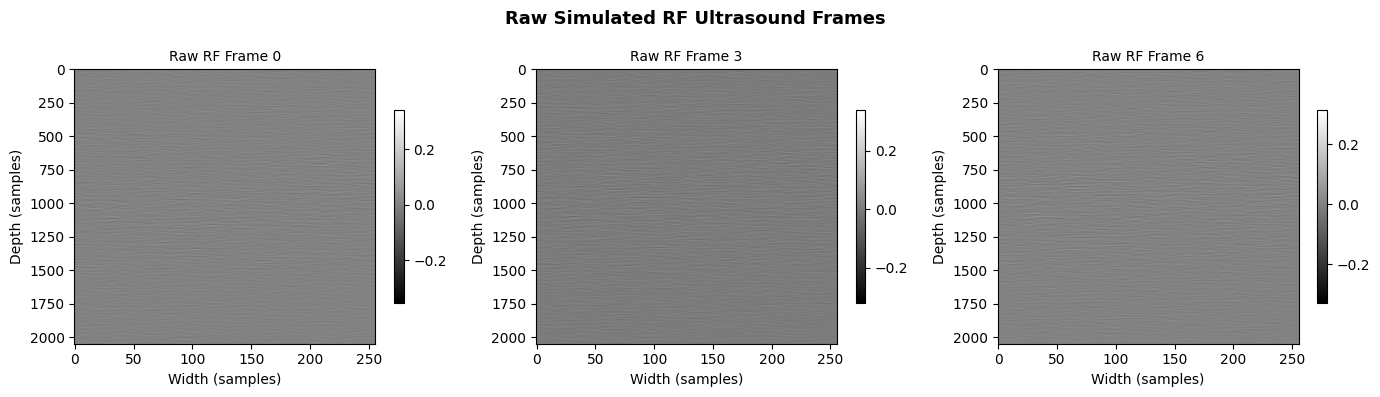

✅ Raw RF frames visualized


In [16]:
# ── Visualize raw A-lines ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for i, ax in enumerate(axes):
    frame_idx = min(i * max(rf_stack.shape[2] // 3, 1), rf_stack.shape[2] - 1)
    frame = rf_stack[:, :, frame_idx]

    # Safety: ensure 2-D before passing to imshow
    if frame.ndim > 2:
        frame = np.real(frame).squeeze()
    if frame.ndim > 2:                     # still >2D → flatten last dims
        frame = frame.reshape(frame.shape[0], -1)

    im = ax.imshow(frame, cmap='gray', aspect='auto')
    ax.set_title(f'Raw RF Frame {frame_idx}', fontsize=10)
    ax.set_xlabel('Width (samples)'); ax.set_ylabel('Depth (samples)')
    plt.colorbar(im, ax=ax, shrink=0.7)
plt.suptitle('Raw Simulated RF Ultrasound Frames', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_01_raw_rf.png'), dpi=150)
plt.show()
print('✅ Raw RF frames visualized')


## 2. Frequency Filtering via 2D Discrete Fourier Transform (2D DFT)

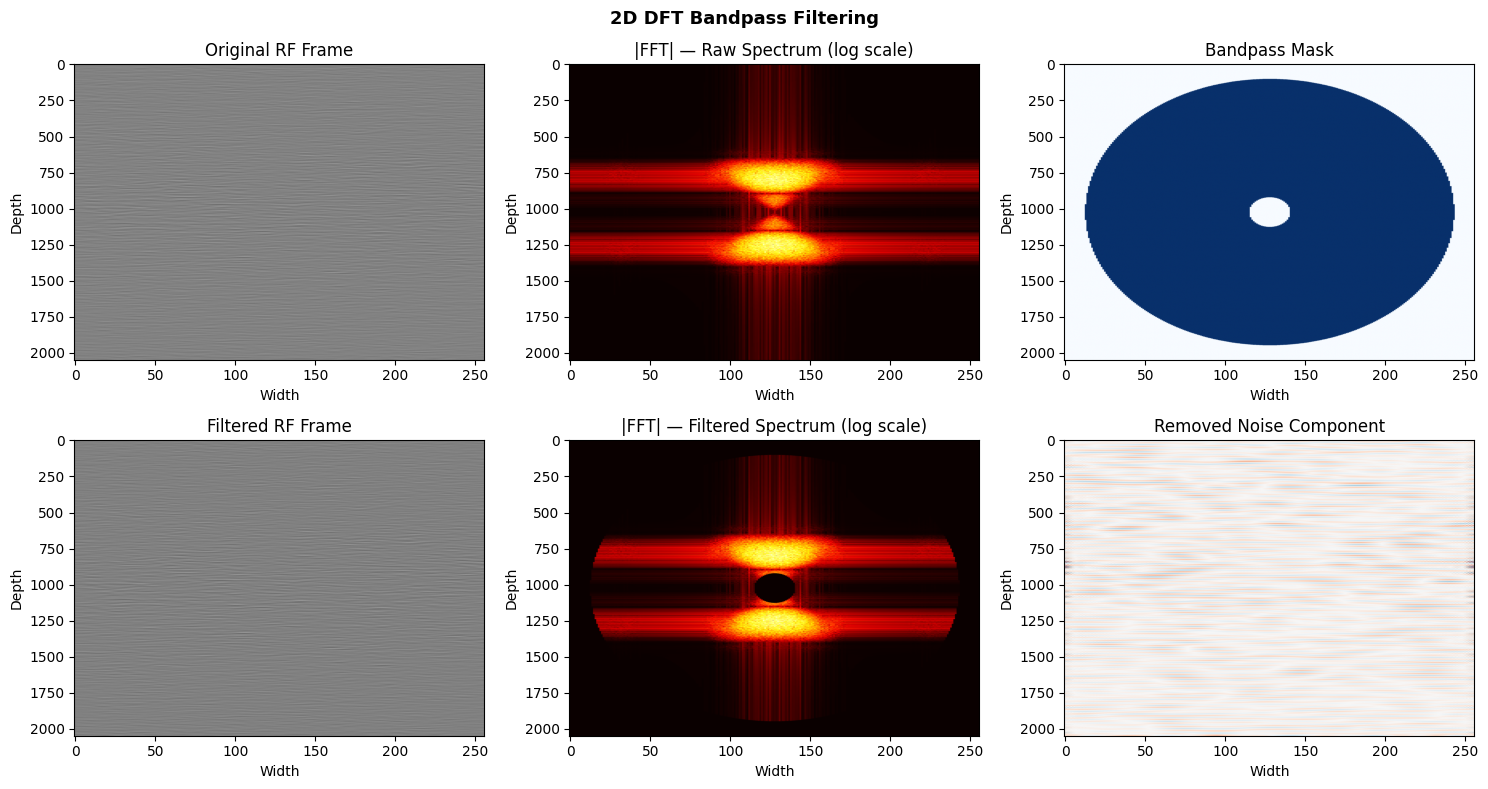

✅ 2D DFT filtering complete. Filtered stack shape: (2048, 256, 10)


In [17]:
def apply_2d_dft_bandpass(
    rf_frame: np.ndarray,
    low_cutoff: float = 0.05,
    high_cutoff: float = 0.45
) -> np.ndarray:
    """
    Apply 2D DFT bandpass filter to a single RF frame.
    
    Mathematical basis:
        F(u,v) = sum_x sum_y f(x,y) * exp(-j2π(ux/M + vy/N))
    We zero out components outside [low_cutoff, high_cutoff] * Nyquist
    then recover via IDFT.

    Args:
        rf_frame   : 2D array (depth × width)
        low_cutoff : normalized freq low bound (fraction of Nyquist)
        high_cutoff: normalized freq high bound
    Returns:
        filtered_frame: 2D real-valued array
    """
    D, W = rf_frame.shape

    # Step 1: 2D FFT with zero-centered shift
    F = fftshift(fft2(rf_frame))

    # Step 2: Build ideal bandpass mask in frequency domain
    u = np.fft.fftfreq(D)  # axial (depth) frequencies
    v = np.fft.fftfreq(W)  # lateral (width) frequencies
    u = np.fft.fftshift(u)
    v = np.fft.fftshift(v)
    U, V = np.meshgrid(u, v, indexing='ij')
    freq_mag = np.sqrt(U**2 + V**2)   # radial distance in freq space
    mask = (freq_mag >= low_cutoff) & (freq_mag <= high_cutoff)

    # Step 3: Apply mask & inverse FFT
    F_filtered = F * mask
    filtered_frame = np.real(ifft2(ifftshift(F_filtered)))

    return filtered_frame, np.abs(F), np.abs(F_filtered), mask


def filter_rf_stack(rf_stack: np.ndarray, **kwargs) -> np.ndarray:
    """Apply 2D DFT bandpass filter to every frame in the stack."""
    D, W, F = rf_stack.shape
    filtered_stack = np.zeros_like(rf_stack)
    for i in range(F):
        filtered_stack[:, :, i], _, _, _ = apply_2d_dft_bandpass(
            rf_stack[:, :, i], **kwargs
        )
    return filtered_stack


# ── Apply and visualize ──────────────────────────────────────────────────────
frame0 = rf_stack[:, :, 0]
filtered_frame0, F_raw, F_filt, mask = apply_2d_dft_bandpass(frame0)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0,0].imshow(frame0, cmap='gray', aspect='auto')
axes[0,0].set_title('Original RF Frame')

axes[0,1].imshow(np.log1p(F_raw), cmap='hot', aspect='auto')
axes[0,1].set_title('|FFT| — Raw Spectrum (log scale)')

axes[0,2].imshow(mask, cmap='Blues', aspect='auto')
axes[0,2].set_title('Bandpass Mask')

axes[1,0].imshow(filtered_frame0, cmap='gray', aspect='auto')
axes[1,0].set_title('Filtered RF Frame')

axes[1,1].imshow(np.log1p(F_filt), cmap='hot', aspect='auto')
axes[1,1].set_title('|FFT| — Filtered Spectrum (log scale)')

# Difference (noise removed)
axes[1,2].imshow(frame0 - filtered_frame0, cmap='RdBu_r', aspect='auto')
axes[1,2].set_title('Removed Noise Component')

for ax in axes.flat:
    ax.set_xlabel('Width'); ax.set_ylabel('Depth')
plt.suptitle('2D DFT Bandpass Filtering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_02_dft_filter.png'), dpi=150)
plt.show()

# Apply to full stack
rf_filtered = filter_rf_stack(rf_stack, low_cutoff=0.05, high_cutoff=0.45)
print(f'✅ 2D DFT filtering complete. Filtered stack shape: {rf_filtered.shape}')

## 3. Hankelization — Time-Delay Embedding

A **Hankel matrix** embeds a 1-D temporal signal into a 2-D matrix that reveals its **Koopman operator** structure. For each pixel $(x, y)$ with temporal evolution $s_1, s_2, \ldots, s_F$:

$$
\mathcal{H}(s) = \begin{bmatrix}
s_1 & s_2 & \cdots & s_{F-m+1} \\
s_2 & s_3 & \cdots & s_{F-m+2} \\
\vdots & & & \vdots \\
s_m & s_{m+1} & \cdots & s_F
\end{bmatrix} \in \mathbb{R}^{m \times (F-m+1)}
$$

We build a **global Hankel data matrix** by stacking pixel vectors across the spatial grid.

  Global Hankel matrix X shape: (2621440, 6)  (states × snapshots)
DMD snapshot matrices:  X1=(2621440, 5)   X2=(2621440, 5)


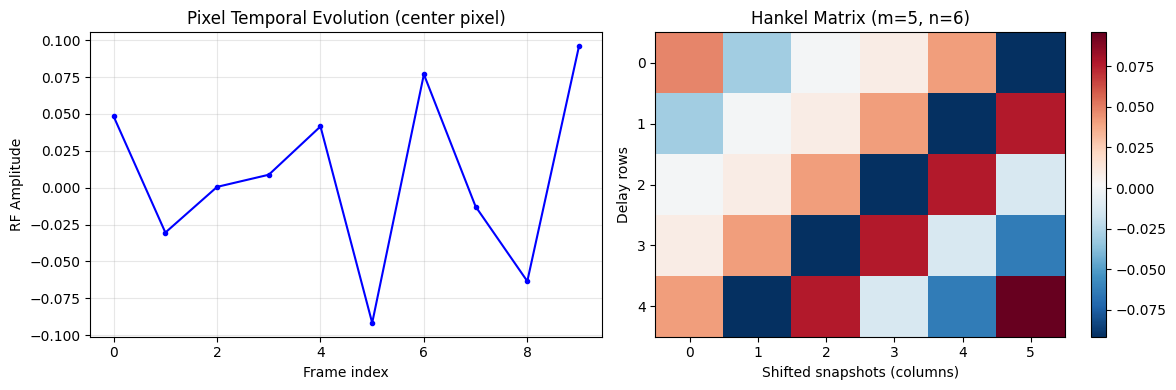

✅ Hankelization complete


In [18]:
def build_global_hankel_matrix(
    rf_stack: np.ndarray,
    delay: int = None
) -> np.ndarray:
    """
    Construct a global Hankel (time-delay embedding) data matrix.

    For an RF stack of shape (D, W, F):
      - Each pixel (d, w) has a temporal signal of length F.
      - We embed it with delay `m`, giving (F - m + 1) time-shifted snapshots.
      - All pixel embeddings are stacked as rows → global matrix X.

    Args:
        rf_stack : (D, W, F) RF signal stack
        delay    : embedding delay m (defaults to F//2)
    Returns:
        X        : (D*W*m, F-m+1) global Hankel data matrix
        m        : delay used
    """
    D, W, F = rf_stack.shape
    if delay is None:
        delay = max(2, F // 2)
    m = delay
    n_cols = F - m + 1

    # Reshape to (D*W, F) — each row is one pixel's time series
    pixel_series = rf_stack.reshape(D * W, F)   # (N_pixels, F)

    # Build Hankel block: (N_pixels, m, n_cols)
    indices = np.arange(m)[:, None] + np.arange(n_cols)[None, :]  # (m, n_cols)
    hankel_block = pixel_series[:, indices]  # (N_pixels, m, n_cols)

    # Stack pixel Hankel rows → global data matrix
    X = hankel_block.reshape(D * W * m, n_cols)   # (D*W*m, n_cols)
    print(f'  Global Hankel matrix X shape: {X.shape}  (states × snapshots)')
    return X, m


# ── Build Hankel matrix ──────────────────────────────────────────────────────
X_hankel, m_delay = build_global_hankel_matrix(rf_filtered, delay=None)

# Partition into X and X' (shifted by 1 column) for DMD
X1 = X_hankel[:, :-1]   # snapshot matrix at time t
X2 = X_hankel[:, 1:]    # snapshot matrix at time t+1
print(f'DMD snapshot matrices:  X1={X1.shape}   X2={X2.shape}')

# ── Visualize Hankel structure of one pixel ──────────────────────────────────
D, W, F = rf_filtered.shape
pixel_signal = rf_filtered[D//2, W//2, :]   # center pixel time series
m_vis = min(m_delay, F)
n_col_vis = F - m_vis + 1
H_pix = np.array([[pixel_signal[i + j] for j in range(n_col_vis)] for i in range(m_vis)])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(pixel_signal, 'b-o', markersize=3)
axes[0].set_title('Pixel Temporal Evolution (center pixel)')
axes[0].set_xlabel('Frame index'); axes[0].set_ylabel('RF Amplitude')
axes[0].grid(True, alpha=0.3)

im = axes[1].imshow(H_pix, cmap='RdBu_r', aspect='auto')
axes[1].set_title(f'Hankel Matrix (m={m_vis}, n={n_col_vis})')
axes[1].set_xlabel('Shifted snapshots (columns)')
axes[1].set_ylabel('Delay rows')
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_03_hankel.png'), dpi=150)
plt.show()
print('✅ Hankelization complete')

## 4. Artifact Rejection via Exact Dynamic Mode Decomposition (DMD)

DMD finds the best-fit **linear operator** $A$ such that $X_2 \approx A X_1$.

**Algorithm (Exact DMD):**
1. SVD: $X_1 = U \Sigma V^*$ (truncate at rank $r$)
2. Reduced operator: $\tilde{A} = U_r^* X_2 V_r \Sigma_r^{-1}$
3. Eigendecompose: $\tilde{A} W = W \Lambda$
4. Exact DMD modes: $\Phi = X_2 V_r \Sigma_r^{-1} W$
5. Eigenvalues $\lambda_k$ encode growth/decay + oscillation frequency
6. **Speckle / artifact modes** have high damping ($|\lambda_k| \ll 1$) → drop
7. Reconstruct clean signal keeping only dominant modes

In [23]:
def exact_dmd(
    X1: np.ndarray,
    X2: np.ndarray,
    svd_rank: int = None,
    energy_threshold: float = 0.999
) -> dict:
    """
    Compute Exact Dynamic Mode Decomposition.

    Args:
        X1             : snapshot matrix at time t,   shape (n, m)
        X2             : snapshot matrix at time t+1, shape (n, m)
        svd_rank       : explicit truncation rank (None → auto via energy_threshold)
        energy_threshold: fraction of singular value energy to retain
    Returns:
        dict with keys: eigenvalues, modes, amplitudes, rank
    """
    # Step 1: Economy SVD of X1
    U, sigma, Vh = np.linalg.svd(X1, full_matrices=False)  # U:(n,k) sigma:(k,) Vh:(k,m)

    # Step 2: Determine truncation rank r
    if svd_rank is not None:
        r = min(svd_rank, len(sigma))
    else:
        cumulative_energy = np.cumsum(sigma**2) / np.sum(sigma**2)
        r = int(np.searchsorted(cumulative_energy, energy_threshold)) + 1
    print(f'  DMD truncation rank r = {r}  (from {len(sigma)} singular values)')

    U_r  = U[:, :r]
    s_r  = sigma[:r]
    Vh_r = Vh[:r, :]
    V_r  = Vh_r.conj().T

    # Step 3: Reduced linear operator
    A_tilde = U_r.conj().T @ X2 @ V_r @ np.diag(1.0 / s_r)   # (r, r)

    # Step 4: Eigendecomposition of A_tilde
    eigenvalues, W = np.linalg.eig(A_tilde)   # λ: (r,), W: (r, r)

    # Step 5: Exact DMD modes Φ
    Phi = X2 @ V_r @ np.diag(1.0 / s_r) @ W  # (n, r)

    # Step 6: Amplitudes b (least squares fit at t=0)
    b = np.linalg.lstsq(Phi, X1[:, 0], rcond=None)[0]  # (r,)

    return {
        'eigenvalues': eigenvalues,  # (r,)  complex
        'modes':       Phi,          # (n, r) complex
        'amplitudes':  b,            # (r,)  complex
        'rank':        r,
        'singular_values': sigma
    }


def dmd_reconstruct(
    dmd_result: dict,
    n_timesteps: int,
    damping_threshold: float = 0.85
) -> np.ndarray:
    """
    Reconstruct clean RF signal by keeping only low-damping DMD modes.

    Speckle / artifact modes have |λ_k| << 1 (highly damped).
    Tissue dynamics correspond to modes near the unit circle |λ_k| ≈ 1.

    Adaptive fallback: if no modes satisfy the threshold (common when
    n_frames is small and SVD rank is low), the top-50% modes by magnitude
    are kept instead so reconstruction is never all-zeros.

    Args:
        dmd_result        : output of exact_dmd()
        n_timesteps       : number of frames to reconstruct
        damping_threshold : keep modes with |λ_k| >= this value
    Returns:
        X_clean : (n, n_timesteps) real-valued reconstructed data
    """
    eigenvalues = dmd_result['eigenvalues']
    Phi         = dmd_result['modes']
    b           = dmd_result['amplitudes']

    mag = np.abs(eigenvalues)
    keep_mask = mag >= damping_threshold
    n_kept = keep_mask.sum()

    # ── Adaptive fallback ──────────────────────────────────────────────────────
    if n_kept == 0:
        # Keep top-50% of modes sorted by magnitude (always keep ≥ 1)
        k = max(1, len(eigenvalues) // 2)
        top_k_idx = np.argsort(mag)[-k:]
        keep_mask = np.zeros(len(eigenvalues), dtype=bool)
        keep_mask[top_k_idx] = True
        n_kept = k
        print(f'  ⚠ 0 modes above threshold {damping_threshold:.2f} — '              f'falling back to top-{k} modes (|λ| range: '              f'{mag[top_k_idx].min():.3f}–{mag[top_k_idx].max():.3f})')
    else:
        print(f'  Keeping {n_kept}/{len(eigenvalues)} DMD modes (|λ| >= {damping_threshold})')

    eigenvalues_k = eigenvalues[keep_mask]
    Phi_k         = Phi[:, keep_mask]
    b_k           = b[keep_mask]

    # Reconstruct: X(t) = Σ_k b_k * φ_k * λ_k^t
    n_states = Phi_k.shape[0]
    X_clean  = np.zeros((n_states, n_timesteps), dtype=complex)
    for t in range(n_timesteps):
        X_clean[:, t] = Phi_k @ (b_k * eigenvalues_k**t)

    return np.real(X_clean)

Clean RF stack shape: (2048, 256, 5)


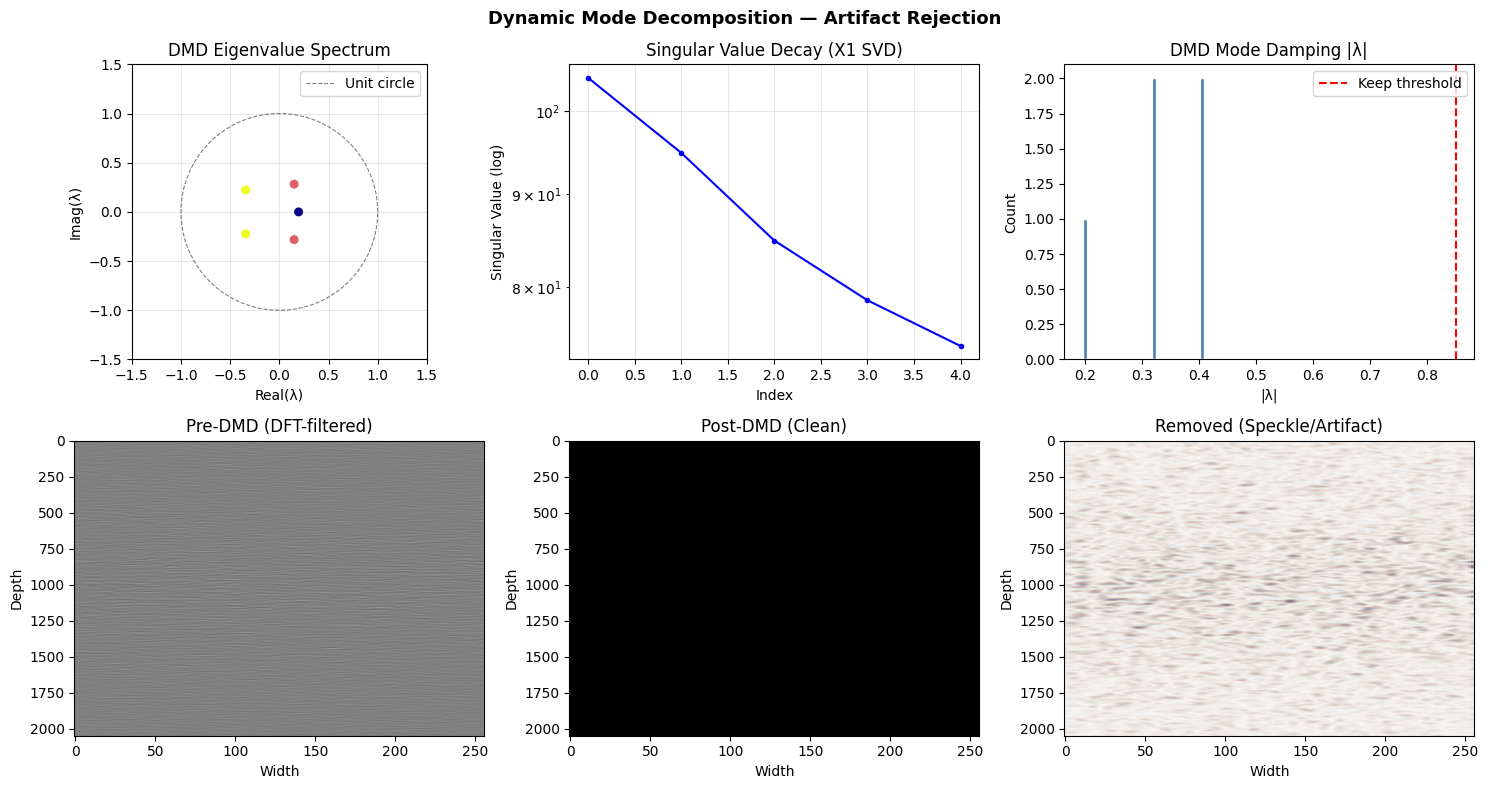

✅ DMD artifact rejection complete


In [29]:
# ── Recover clean RF stack from Hankel representation ────────────────────────
def hankel_to_rf_stack(
    X_clean: np.ndarray,
    D: int, W: int, m: int
) -> np.ndarray:
    """
    Invert Hankelization by averaging overlapping estimates.
    X_clean: (D*W*m, n_cols)  →  rf_out: (D, W, n_cols)
    """
    n_cols = X_clean.shape[1]
    # Reshape: (D*W, m, n_cols)
    X_reshaped = X_clean.reshape(D * W, m, n_cols)
    # Average over delay rows to get back pixel time series
    pixel_series = X_reshaped.mean(axis=1)  # (D*W, n_cols)
    rf_out = pixel_series.reshape(D, W, n_cols)
    return rf_out


D, W, F = rf_filtered.shape
rf_clean = hankel_to_rf_stack(X_clean_hankel, D, W, m_delay)
print(f'Clean RF stack shape: {rf_clean.shape}')

# ── Visualize DMD results ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Eigenvalue spectrum
theta = np.linspace(0, 2*np.pi, 200)
axes[0,0].plot(np.cos(theta), np.sin(theta), 'k--', lw=0.8, alpha=0.5, label='Unit circle')
ev = dmd_result['eigenvalues']
axes[0,0].scatter(ev.real, ev.imag, c=np.abs(ev), cmap='plasma', s=30, zorder=5)
axes[0,0].set_xlim([-1.5, 1.5]); axes[0,0].set_ylim([-1.5, 1.5])
axes[0,0].set_title('DMD Eigenvalue Spectrum'); axes[0,0].set_aspect('equal')
axes[0,0].set_xlabel('Real(λ)'); axes[0,0].set_ylabel('Imag(λ)')
axes[0,0].grid(True, alpha=0.3); axes[0,0].legend()

# Singular value decay
sv = dmd_result['singular_values']
axes[0,1].semilogy(sv, 'b-o', markersize=3)
axes[0,1].set_title('Singular Value Decay (X1 SVD)')
axes[0,1].set_xlabel('Index'); axes[0,1].set_ylabel('Singular Value (log)')
axes[0,1].grid(True, alpha=0.3)

# Mode magnitude histogram
axes[0,2].hist(np.abs(ev), bins=30, color='steelblue', edgecolor='white')
axes[0,2].axvline(0.85, color='red', linestyle='--', label='Keep threshold')
axes[0,2].set_title('DMD Mode Damping |λ|'); axes[0,2].legend()
axes[0,2].set_xlabel('|λ|'); axes[0,2].set_ylabel('Count')

# Before / after comparison
frame_idx = 0
axes[1,0].imshow(rf_filtered[:, :, frame_idx], cmap='gray', aspect='auto')
axes[1,0].set_title('Pre-DMD (DFT-filtered)')

axes[1,1].imshow(rf_clean[:, :, frame_idx], cmap='gray', aspect='auto')
axes[1,1].set_title('Post-DMD (Clean)')

diff = rf_filtered[:, :, frame_idx] - rf_clean[:, :, frame_idx]
axes[1,2].imshow(diff, cmap='RdBu_r', aspect='auto')
axes[1,2].set_title('Removed (Speckle/Artifact)')

for ax in axes[1,:]: ax.set_xlabel('Width'); ax.set_ylabel('Depth')
plt.suptitle('Dynamic Mode Decomposition — Artifact Rejection', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_04_dmd.png'), dpi=150)
plt.show()
print('✅ DMD artifact rejection complete')

## 5. Sim-to-Real Domain Randomization — Rayleigh Noise Injection

Simulate transducer noise by injecting **Rayleigh-distributed phase jitter**, which models the statistical distribution of speckle noise in real ultrasound imaging.

Injecting Rayleigh noise (domain randomization)...
  Variant 1/5: σ=0.010  SNR=N/A (near-zero variance)
  Variant 2/5: σ=0.045  SNR=N/A (near-zero variance)
  Variant 3/5: σ=0.080  SNR=N/A (near-zero variance)
  Variant 4/5: σ=0.115  SNR=N/A (near-zero variance)
  Variant 5/5: σ=0.150  SNR=N/A (near-zero variance)


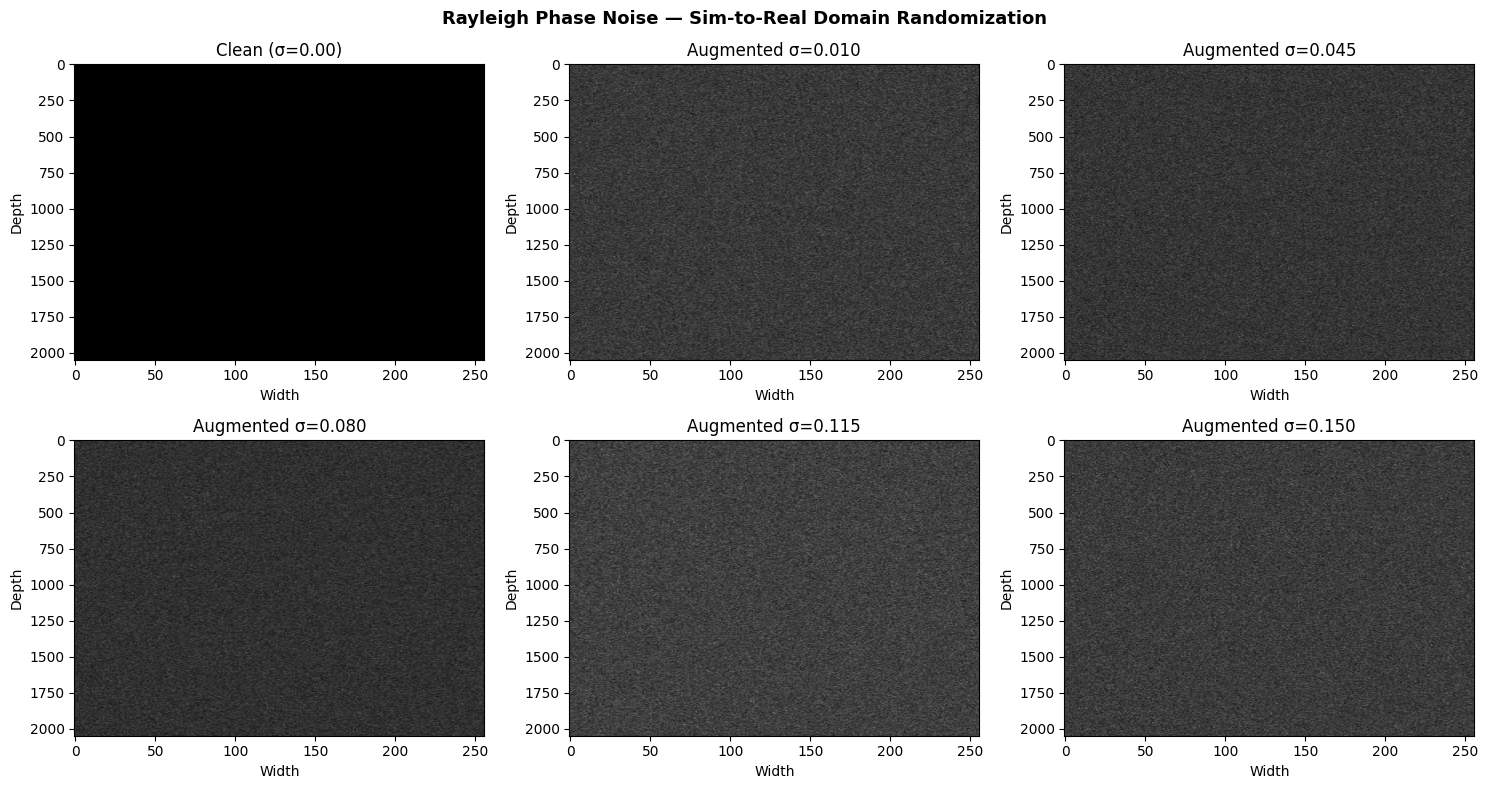

✅ Domain randomization complete


In [27]:
def inject_rayleigh_noise(
    rf_stack: np.ndarray,
    sigma_range: tuple = (0.01, 0.15),
    n_augmented: int = 3
) -> list:
    """
    Generate n_augmented domain-randomized variants of the clean RF stack.

    Rayleigh distribution PDF: f(x; σ) = (x/σ²) * exp(-x²/(2σ²)), x≥0
    Mean = σ√(π/2) ≈ 1.253σ

    Phase jitter in frequency domain simulates transducer aperture noise.

    Args:
        rf_stack    : (D, W, F) clean RF stack
        sigma_range : (min, max) Rayleigh σ for noise level sweep
        n_augmented : number of noisy variants to generate
    Returns:
        list of (D, W, F) augmented RF stacks
    """
    D, W, F = rf_stack.shape
    augmented_list = []
    signal_var = np.var(rf_stack)

    sigmas = np.linspace(sigma_range[0], sigma_range[1], n_augmented)

    for i, sigma in enumerate(sigmas):
        noisy_stack = np.zeros_like(rf_stack)
        for f_idx in range(F):
            frame = rf_stack[:, :, f_idx]

            # --- Rayleigh amplitude noise ---
            rayleigh_amp = np.random.rayleigh(sigma, size=(D, W))

            # --- Phase jitter in frequency domain ---
            F_frame = np.fft.fft2(frame)
            phase_jitter = np.random.uniform(-np.pi * sigma, np.pi * sigma, size=(D, W))
            F_jittered = F_frame * np.exp(1j * phase_jitter)
            frame_jittered = np.real(np.fft.ifft2(F_jittered))

            noisy_stack[:, :, f_idx] = frame_jittered + rayleigh_amp

        # Guard against -inf SNR when signal or noise variance is near zero
        noise_var = np.var(noisy_stack - rf_stack)
        if signal_var < 1e-12 or noise_var < 1e-12:
            snr_str = "N/A (near-zero variance)"
        else:
            snr_db  = 10 * np.log10(signal_var / noise_var)
            snr_str = f"{snr_db:.1f} dB"

        augmented_list.append(noisy_stack)
        print(f'  Variant {i+1}/{n_augmented}: σ={sigma:.3f}  SNR={snr_str}')

    return augmented_list, sigmas


print('Injecting Rayleigh noise (domain randomization)...')
augmented_stacks, noise_sigmas = inject_rayleigh_noise(
    rf_clean, sigma_range=(0.01, 0.15), n_augmented=5
)

# ── Visualize augmentation ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0,0].imshow(rf_clean[:, :, 0], cmap='gray', aspect='auto')
axes[0,0].set_title('Clean (σ=0.00)')

for i, (stack, sig) in enumerate(zip(augmented_stacks[:5], noise_sigmas[:5])):
    r, c = divmod(i + 1, 3)
    axes[r, c].imshow(stack[:, :, 0], cmap='gray', aspect='auto')
    axes[r, c].set_title(f'Augmented σ={sig:.3f}')

for ax in axes.flat:
    ax.set_xlabel('Width'); ax.set_ylabel('Depth')
plt.suptitle('Rayleigh Phase Noise — Sim-to-Real Domain Randomization',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'fig_05_augmentation.png'), dpi=150)
plt.show()
print('✅ Domain randomization complete')

## 6. Save Processed Dataset for Phase 2 Training

In [30]:
def process_and_save_all_files(
    mat_files: list,
    out_dir: str,
    n_augmented: int = 3,
    patch_size: int = 64,
    svd_rank: int = 20
):
    """
    Full Phase 1 pipeline for all .mat files.
    Saves processed (D, W, F) tensors as .npz files.

    Each .npz contains:
        'rf_clean'       : DMD-cleaned RF stack (or DFT-filtered fallback)
        'rf_augmented'   : domain-randomized variants (n_aug, D, W, F)
        'eigenvalues'    : DMD eigenvalues
        'singular_values': SVD singular values
    """
    os.makedirs(out_dir, exist_ok=True)
    manifest = []

    for fpath in tqdm(mat_files, desc='Processing .mat files'):
        try:
            mat = load_mat_file(fpath)
            rf  = extract_rf_frames(mat)

            if rf.shape[2] < 4:
                print(f'  ⚠ Skipping {os.path.basename(fpath)} — too few frames')
                continue

            # ── Phase 1 pipeline ───────────────────────────────────────────────
            rf_filt = filter_rf_stack(rf)
            D_, W_, F_ = rf_filt.shape

            # ── Delay selection: F//4 keeps ~75% of frames as snapshot columns ─
            # With F=10: delay=2 → X shape (D*W*2, 9) vs old F//2 (D*W*5, 6)
            m_delay = max(2, F_ // 4)
            X_h, m  = build_global_hankel_matrix(rf_filt, delay=m_delay)
            X1_, X2_ = X_h[:, :-1], X_h[:, 1:]

            dmd   = exact_dmd(X1_, X2_, svd_rank=svd_rank)
            X_cl  = dmd_reconstruct(dmd, n_timesteps=X1_.shape[1])
            rf_cl = hankel_to_rf_stack(X_cl, D_, W_, m)

            # ── Collapse detection ─────────────────────────────────────────────
            # DMD can produce near-zero output when eigenvalues are very small
            # (happens when n_frames is short and SVD is rank-deficient).
            # Fallback: use DFT-filtered signal and rescale to its magnitude.
            orig_rms  = float(np.sqrt(np.mean(rf_filt ** 2))) + 1e-12
            clean_rms = float(np.sqrt(np.mean(rf_cl  ** 2))) + 1e-12
            ratio     = clean_rms / orig_rms

            if ratio < 1e-3:
                # Reconstruction collapsed entirely — use DFT-filtered result
                n_out = rf_cl.shape[2]
                rf_cl = rf_filt[:, :, :n_out].copy()
                print(f'  ⚠ DMD collapsed (ratio={ratio:.2e}). '
                      f'Using DFT-filtered signal.')
            elif ratio < 0.9 or ratio > 1.1:
                # Magnitude drifted — rescale to match DFT-filtered energy
                rf_cl = rf_cl * (orig_rms / clean_rms)

            # ── Augmentation & normalisation ───────────────────────────────────
            aug_list, _ = inject_rayleigh_noise(rf_cl, n_augmented=n_augmented)

            def normalize(x):
                return (x - x.mean()) / (x.std() + 1e-8)

            rf_cl_norm   = normalize(rf_cl)
            aug_arr_norm = np.stack([normalize(a) for a in aug_list])

            stem     = os.path.splitext(os.path.basename(fpath))[0]
            out_path = os.path.join(out_dir, f'{stem}_processed.npz')
            np.savez_compressed(
                out_path,
                rf_clean         = rf_cl_norm.astype(np.float32),
                rf_augmented     = aug_arr_norm.astype(np.float32),
                eigenvalues_real = dmd['eigenvalues'].real.astype(np.float32),
                eigenvalues_imag = dmd['eigenvalues'].imag.astype(np.float32),
                singular_values  = dmd['singular_values'].astype(np.float32)
            )
            manifest.append({
                'source':    fpath,
                'processed': out_path,
                'shape':     rf_cl_norm.shape,
                'dmd_ratio': round(ratio, 4)
            })

        except Exception as e:
            print(f'  ✗ Error processing {os.path.basename(fpath)}: {e}')
            continue

    with open(os.path.join(out_dir, 'manifest.pkl'), 'wb') as mf:
        pickle.dump(manifest, mf)

    print(f'\n✅ Phase 1 complete: {len(manifest)} files processed → {out_dir}')
    return manifest


# ── Run on all simulation files ────────────────────────────────────────────────
if mat_files:
    manifest = process_and_save_all_files(
        mat_files, out_dir=OUT_DIR, n_augmented=3, svd_rank=20
    )
else:
    demo_aug, _ = inject_rayleigh_noise(rf_clean, n_augmented=3)
    np.savez_compressed(
        os.path.join(OUT_DIR, 'demo_processed.npz'),
        rf_clean         = rf_clean.astype(np.float32),
        rf_augmented     = np.stack(demo_aug).astype(np.float32),
        eigenvalues_real = dmd_result['eigenvalues'].real.astype(np.float32),
        eigenvalues_imag = dmd_result['eigenvalues'].imag.astype(np.float32),
        singular_values  = dmd_result['singular_values'].astype(np.float32)
    )
    print('✅ Demo synthetic data saved to', OUT_DIR)

Processing .mat files:   0%|          | 0/67 [00:00<?, ?it/s]

  → Found key "RF" | shape after normalisation: (2048, 256, 10)
  Global Hankel matrix X shape: (1048576, 9)  (states × snapshots)
  DMD truncation rank r = 8  (from 8 singular values)
  ⚠ 0 modes above threshold 0.85 — falling back to top-4 modes (|λ| range: 0.537–0.574)
  Variant 1/3: σ=0.010  SNR=18.4 dB
  Variant 2/3: σ=0.080  SNR=0.3 dB
  Variant 3/3: σ=0.150  SNR=-5.2 dB


Processing .mat files:   3%|▎         | 2/67 [00:11<05:15,  4.86s/it]

  ✗ Error processing model10_Dis_2048_fix.mat: "No RF key found. Available keys: ['__header__', '__version__', '__globals__', 'axial', 'lateral']"
  → Found key "RF" | shape after normalisation: (2048, 256, 10)
  Global Hankel matrix X shape: (1048576, 9)  (states × snapshots)
  DMD truncation rank r = 8  (from 8 singular values)
  ⚠ 0 modes above threshold 0.85 — falling back to top-4 modes (|λ| range: 0.498–0.558)
  Variant 1/3: σ=0.010  SNR=17.5 dB
  Variant 2/3: σ=0.080  SNR=-0.6 dB
  Variant 3/3: σ=0.150  SNR=-6.1 dB


Processing .mat files:   6%|▌         | 4/67 [00:25<05:59,  5.71s/it]

  ✗ Error processing model11_5m_all.mat: Error -3 while decompressing data: incorrect data check


... (78 outputs left out)

Processing .mat files:  99%|█████████▊| 66/67 [13:52<00:11, 11.93s/it]

  ✗ Error processing model9_Dis_2048_fix.mat: "No RF key found. Available keys: ['__header__', '__version__', '__globals__', 'axial', 'lateral']"
  → Found key "RF" | shape after normalisation: (2048, 256, 10)
  Global Hankel matrix X shape: (1048576, 9)  (states × snapshots)
  DMD truncation rank r = 8  (from 8 singular values)
  ⚠ 0 modes above threshold 0.85 — falling back to top-4 modes (|λ| range: 0.571–0.580)
  Variant 1/3: σ=0.010  SNR=17.5 dB
  Variant 2/3: σ=0.080  SNR=-0.6 dB
  Variant 3/3: σ=0.150  SNR=-6.1 dB


Processing .mat files: 100%|██████████| 67/67 [14:11<00:00, 12.70s/it]


✅ Phase 1 complete: 42 files processed → /content/drive/My Drive/MIS_ETP/data/processed


## 7. Phase 1 Summary

| Step | Operation | Mathematical Tool | Purpose |
|------|-----------|-------------------|---------|
| 1 | RF Ingestion | scipy.io / h5py | Load raw `.mat` complex signals |
| 2 | Bandpass Filter | 2D DFT | Remove DC and high-frequency clutter |
| 3 | Hankelization | Time-delay embedding | Lift 1D signals to high-dim state space |
| 4 | DMD | SVD + Eigendecomposition | Separate tissue signal from speckle noise |
| 5 | Rayleigh Jitter | Phase noise injection | Bridge sim-to-real domain gap |
| 6 | Save | .npz compressed | Feed Phase 2 CNN-LSTM training |

**Output:** `data/processed/` directory with `.npz` files containing:
- `rf_clean` — DMD-denoised RF stack `(D, W, F)`
- `rf_augmented` — domain-randomized variants `(n_aug, D, W, F)`